An embedded SVG font, then a parse/re-serialize round trip.

Run it as ``python font_roundtrip.py [OUTPUT_DIR]`` or open ``font_roundtrip.ipynb`` to see each step.

In [1]:
import sys
import tempfile
import warnings
from pathlib import Path

import svgwriter as svg

An SVG font is a `Font` with glyphs drawn as path data. This one has three block letters,
a missing-glyph box and a kerning pair.

In [2]:
EM = 1000
ADVANCE = 600

doc = svg.Document(400, 120)
font = doc.define(svg.Font(svg.FontFace(font_family="Blocks", units_per_em=EM, ascent=800, descent=-200), horiz_adv_x=ADVANCE))
font.add(svg.MissingGlyph(d="M50 0 h500 v700 h-500 z"))
font.glyph("I", "M250 0 h100 v700 h-100 z")
font.glyph("L", "M100 0 h400 v100 h-300 v600 h-100 z")
font.glyph("T", "M250 0 h100 v600 h200 v100 h-500 v-100 h200 z")
font.add(svg.HKern.pair("L", "T", 120))

<HKern hkern u1='L' u2='T' k='120'>

A style rule selects the font by name, and text with that class is drawn from the glyphs above.
(The preview below is rasterized by skia, which does not read SVG fonts, so it substitutes a system
font; browsers and the saved file use the embedded glyphs.)

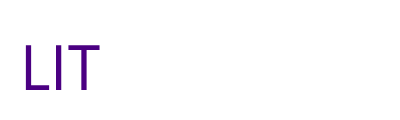

In [3]:
warnings.filterwarnings("ignore", message="font 'Blocks' not found")
sheet = svg.StyleSheet().rule(".big", font_family="Blocks", font_size=64, fill="indigo")
doc.root.insert(0, svg.StyleElement(sheet))
doc.add(svg.Text("LIT", x=20, y=90, class_="big"))
doc

Save it, parse the file back and save the copy: the two files must be identical.
Pass a folder as the first argument to choose where they go.

In [4]:
args = sys.argv[1:2]
out = Path(args[0]) if args and not args[0].startswith("-") else Path(tempfile.mkdtemp(prefix="svgwriter-"))
original = out / "font.svg"
doc.save(original)
copy = out / "font_copy.svg"
svg.Document.open(original).save(copy)
identical = original.read_text(encoding="utf-8") == copy.read_text(encoding="utf-8")
print("round trip:", "identical" if identical else "DIFFERENT")
if not identical:
    sys.exit(1)

round trip: identical
